# Patient Admission and Discharge Trend Analysis
**Course:** Data Analytics Using Python (CSL0312) | **Program:** B.Tech CSE (AIML), Semester III, Section E  
**Team:** Sanjay Pal (BETN1AI25087), Kunal Singh (BETN1AI25114) | **Mentor:** Dr. Sanjay Jain  
**Dataset:** Diabetes 130-US Hospitals for Years 1999-2008 (UCI ML Repository) - file `diabetic_data.csv` must be in the same folder.

> **Scope note:** this dataset has *no admission/discharge dates*, so calendar trends are not possible. "Peak" is analysed as peak admission/discharge *categories*, and length of stay (LOS) is the workload measure.

## 1. Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep'); plt.rcParams['figure.dpi']=110

## 2. Dataset understanding

In [2]:
raw = pd.read_csv('diabetic_data.csv', na_values=['?'], low_memory=False)
print('Shape:', raw.shape)
print('Unique patients:', raw.patient_nbr.nunique(), '| duplicate rows:', raw.duplicated().sum(), '| duplicate encounter ids:', raw.encounter_id.duplicated().sum())
print('Date-like columns:', [c for c in raw.columns if 'date' in c.lower()] or 'NONE')
raw.head()

Shape: (101766, 50)


Unique patients: 71518 | duplicate rows: 0 | duplicate encounter ids: 0
Date-like columns: NONE


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
raw.info(verbose=False); raw[['time_in_hospital','num_lab_procedures','num_procedures','num_medications','number_inpatient']].describe()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Columns: 50 entries, encounter_id to readmitted
dtypes: int64(13), str(37)
memory usage: 38.8 MB


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_inpatient
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.635566
std,2.985108,19.674362,1.705807,8.127566,1.262863
min,1.000000,1.000000,0.000000,1.000000,0.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000
75%,6.000000,57.000000,2.000000,20.000000,1.000000
max,14.000000,132.000000,6.000000,81.000000,21.000000


## 3. Data cleaning & preprocessing

weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64


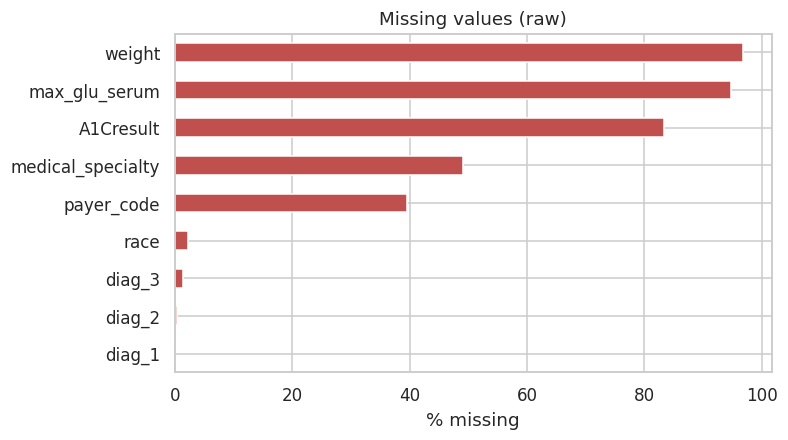

In [4]:
miss = (raw.isna().mean()*100); miss = miss[miss>0].sort_values(ascending=False)
print(miss.round(2))
miss.plot.barh(color='#c0504d', figsize=(7,4)); plt.gca().invert_yaxis(); plt.xlabel('% missing'); plt.title('Missing values (raw)'); plt.show()

In [5]:
df = raw.drop(columns=['weight','payer_code'])                     # 96.9% / 39.6% missing
const = [c for c in df.columns if df[c].nunique()==1]; print('Constant columns dropped:', const)
df = df.drop(columns=const)
df['medical_specialty'] = df['medical_specialty'].fillna('Unknown'); df['race'] = df['race'].fillna('Unknown')
df[['max_glu_serum','A1Cresult']] = df[['max_glu_serum','A1Cresult']].fillna('Not tested')  # missing = test not done
n0=len(df); df = df[df.gender!='Unknown/Invalid']; print('Invalid gender rows removed:', n0-len(df))

Constant columns dropped: ['examide', 'citoglipton']
Invalid gender rows removed: 3


In [6]:
adm_type = {1:'Emergency',2:'Urgent',3:'Elective',4:'Newborn',5:'Not available',6:'Not available',7:'Trauma center',8:'Not available'}
src = {1:'Physician referral',2:'Clinic referral',3:'HMO referral',4:'Transfer: hospital',5:'Transfer: SNF',6:'Transfer: other facility',7:'Emergency room',22:'Transfer within hospital',25:'Ambulatory surgery'}
def discharge_group(i):
    if i==1: return 'Home'
    if i in (6,8): return 'Home with health service'
    if i in (2,3,4,5,15,16,17,22,23,24,27,28,29,30): return 'Facility transfer / care'
    if i in (11,13,14,19,20,21): return 'Expired / hospice'
    if i==7: return 'Left against advice'
    return 'Other / unknown'
def icd_group(x):
    if pd.isna(x): return 'Unknown'
    if str(x).startswith(('E','V')): return 'Other'
    v=float(x)
    if 390<=v<=459 or v==785: return 'Circulatory'
    if 460<=v<=519 or v==786: return 'Respiratory'
    if 520<=v<=579 or v==787: return 'Digestive'
    if int(v)==250: return 'Diabetes'
    if 800<=v<=999: return 'Injury'
    if 710<=v<=739: return 'Musculoskeletal'
    if 580<=v<=629 or v==788: return 'Genitourinary'
    if 140<=v<=239: return 'Neoplasms'
    return 'Other'
df['admission_type']  = df.admission_type_id.map(adm_type)
df['admission_source']= df.admission_source_id.map(src).fillna('Other / unknown')
df['discharge_group'] = df.discharge_disposition_id.map(discharge_group)
df['primary_diag_group'] = df.diag_1.map(icd_group)
df['readmit_30'] = (df.readmitted=='<30').astype(int)
age_order = sorted(df.age.unique(), key=lambda s:int(s.strip('[').split('-')[0]))
df['age'] = pd.Categorical(df.age, categories=age_order, ordered=True)
df['age_mid'] = df.age.map({a:int(a.strip('[').split('-')[0])+5 for a in age_order}).astype(int)
print('Cleaned shape:', df.shape)
df.to_csv('cleaned_diabetic_data.csv', index=False)

Cleaned shape:

 (101763, 52)


In [7]:
# Patients who died / entered hospice cannot be readmitted -> excluded from readmission analysis only
rd = df[df.discharge_group!='Expired / hospice']
print('Readmission-eligible encounters:', len(rd))

Readmission-eligible encounters: 99340


## 4. Exploratory data analysis

In [8]:
los = df.time_in_hospital
print(f'LOS mean={los.mean():.2f}  median={los.median()}  mode={los.mode()[0]}  std={los.std():.2f}  skew={los.skew():.2f}')
q1,q3 = los.quantile([.25,.75]); fence=q3+1.5*(q3-q1); print('IQR upper fence:', fence, '| encounters above:', (los>fence).sum())

LOS mean=4.40  median=4.0  mode=3  std=2.99  skew=1.13
IQR upper fence: 12.0 | encounters above: 2252


In [9]:
def summary(col):
    t = df[col].value_counts().rename('encounters').to_frame()
    t['% of total'] = (t.encounters/len(df)*100).round(2)
    t['mean LOS'] = df.groupby(col, observed=True).time_in_hospital.mean().round(2)
    return t
for c in ['admission_type','admission_source','discharge_group','primary_diag_group','gender']:
    display(summary(c))
display(summary('age').sort_index())

,encounters,% of total,mean LOS
admission_type,,,
Emergency,53988,53.05,4.38
Elective,18868,18.54,4.32
Urgent,18480,18.16,4.61
Not available,10396,10.22,4.24
Trauma center,21,0.02,4.86
Newborn,10,0.01,3.20


,encounters,% of total,mean LOS
admission_source,,,
Emergency room,57492,56.50,4.39
Physician referral,29564,29.05,4.26
Other / unknown,7096,6.97,4.15
Transfer: hospital,3187,3.13,5.81
Transfer: other facility,2264,2.22,4.43
Clinic referral,1104,1.08,4.68
Transfer: SNF,855,0.84,5.83
HMO referral,187,0.18,4.82
Transfer within hospital,12,0.01,10.00


,encounters,% of total,mean LOS
discharge_group,,,
Home,60232,59.19,3.70
Facility transfer / care,20765,20.41,5.57
Home with health service,13010,12.78,5.45
Other / unknown,4710,4.63,5.04
Expired / hospice,2423,2.38,5.08
Left against advice,623,0.61,2.84


,encounters,% of total,mean LOS
primary_diag_group,,,
Circulatory,30436,29.91,4.23
Other,18172,17.86,4.76
Respiratory,14423,14.17,4.23
Digestive,9475,9.31,4.36
Diabetes,8757,8.61,4.34
Injury,6972,6.85,4.62
Genitourinary,5117,5.03,4.24
Musculoskeletal,4957,4.87,3.92
Neoplasms,3433,3.37,5.36


,encounters,% of total,mean LOS
gender,,,
Female,54708,53.76,4.48
Male,47055,46.24,4.30


,encounters,% of total,mean LOS
age,,,
[0-10),161,0.16,2.55
[10-20),691,0.68,3.19
[20-30),1657,1.63,3.56
[30-40),3775,3.71,3.80
[40-50),9685,9.52,4.04
[50-60),17256,16.96,4.13
[60-70),22482,22.09,4.38
[70-80),26066,25.61,4.59
[80-90),17197,16.90,4.81


In [10]:
print('Readmission outcome (eligible encounters):'); print((rd.readmitted.value_counts(normalize=True)*100).round(2))
print('Overall 30-day readmission rate: %.2f%%' % (rd.readmit_30.mean()*100))

Readmission outcome (eligible encounters):


readmitted
NO     52.87
>30    35.74
<30    11.39
Name: proportion, dtype: float64
Overall 30-day readmission rate: 11.39%


## 5. Data visualization

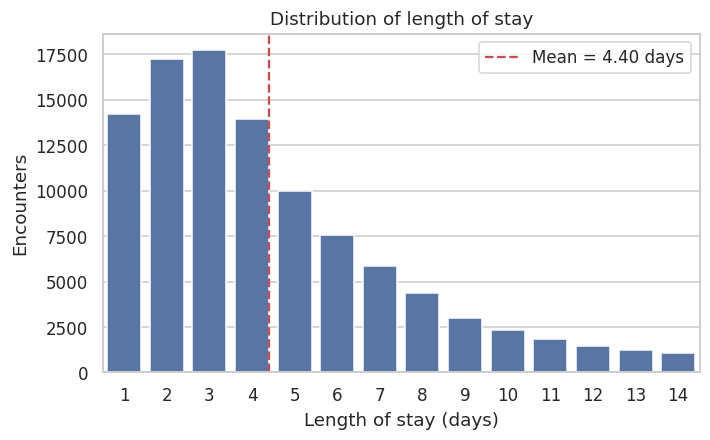

In [11]:
plt.figure(figsize=(7,4)); sns.countplot(x='time_in_hospital', data=df, color='#4c72b0')
plt.axvline(los.mean()-1, color='r', ls='--', label=f'Mean = {los.mean():.2f} days'); plt.legend()
plt.xlabel('Length of stay (days)'); plt.ylabel('Encounters'); plt.title('Distribution of length of stay'); plt.show()

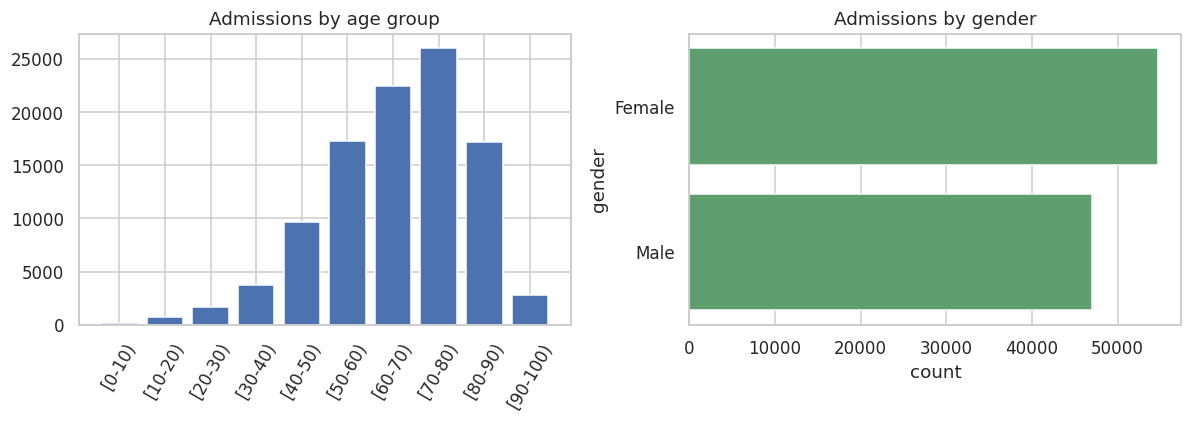

In [12]:
fig,ax = plt.subplots(1,2,figsize=(11,4))
vc=df.age.value_counts().sort_index(); ax[0].bar(range(len(vc)),vc.values,color='#4c72b0'); ax[0].set_xticks(range(len(vc))); ax[0].set_xticklabels(vc.index,rotation=60); ax[0].set_title('Admissions by age group')
sns.countplot(y='gender',data=df,ax=ax[1],color='#55a868'); ax[1].set_title('Admissions by gender'); plt.tight_layout(); plt.show()

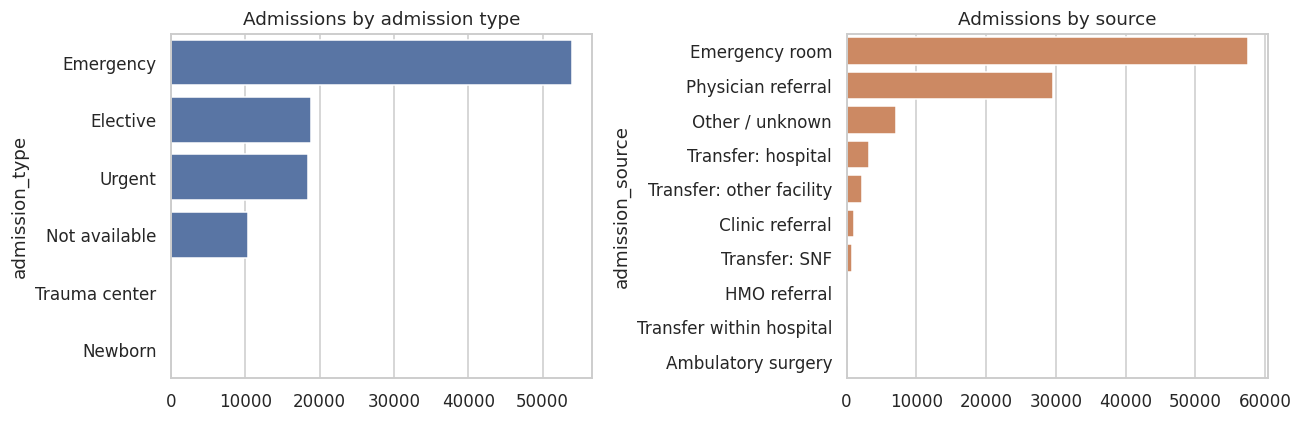

In [13]:
fig,ax = plt.subplots(1,2,figsize=(12,4))
vc=df.admission_type.value_counts(); sns.barplot(x=vc.values,y=vc.index,ax=ax[0],color='#4c72b0'); ax[0].set_title('Admissions by admission type')
vc=df.admission_source.value_counts(); sns.barplot(x=vc.values,y=vc.index,ax=ax[1],color='#dd8452'); ax[1].set_title('Admissions by source'); plt.tight_layout(); plt.show()

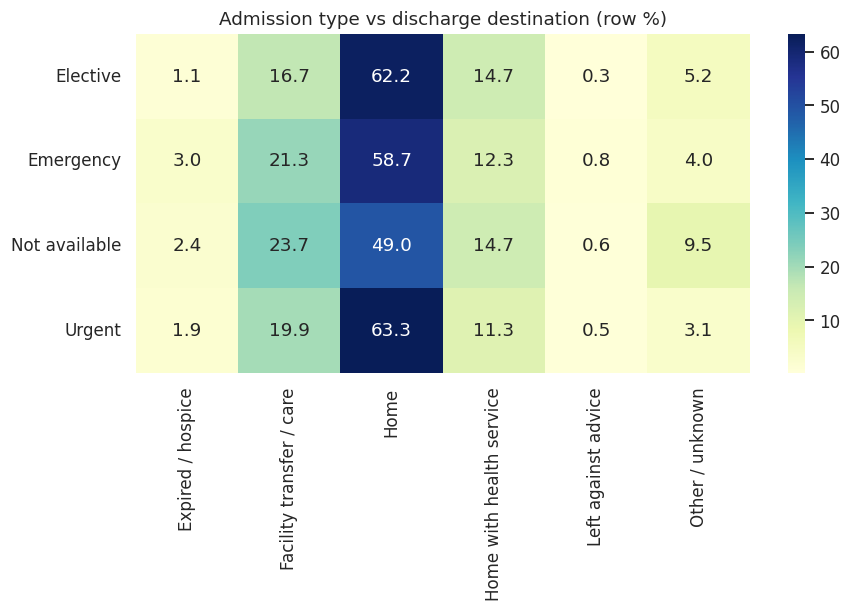

In [14]:
ct = pd.crosstab(df.admission_type, df.discharge_group, normalize='index')*100
plt.figure(figsize=(9,4)); sns.heatmap(ct.drop(index=['Newborn','Trauma center']), annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Admission type vs discharge destination (row %)'); plt.ylabel(''); plt.xlabel(''); plt.show()

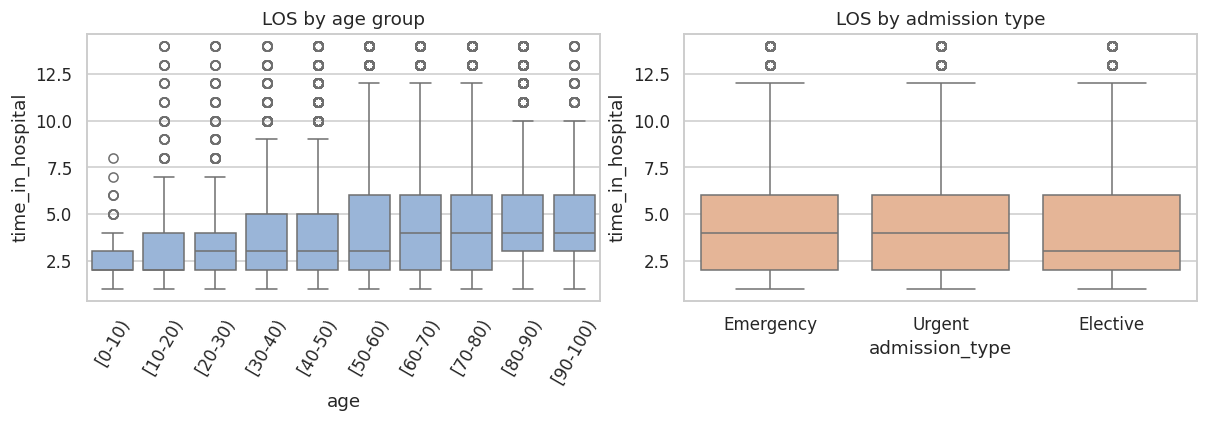

In [15]:
fig,ax = plt.subplots(1,2,figsize=(11,4))
sns.boxplot(x='age',y='time_in_hospital',data=df,ax=ax[0],color='#8fb4e3'); ax[0].tick_params(axis='x',rotation=60); ax[0].set_title('LOS by age group')
o=df[df.admission_type.isin(['Emergency','Urgent','Elective'])]; sns.boxplot(x='admission_type',y='time_in_hospital',data=o,ax=ax[1],color='#f2b28a'); ax[1].set_title('LOS by admission type'); plt.tight_layout(); plt.show()

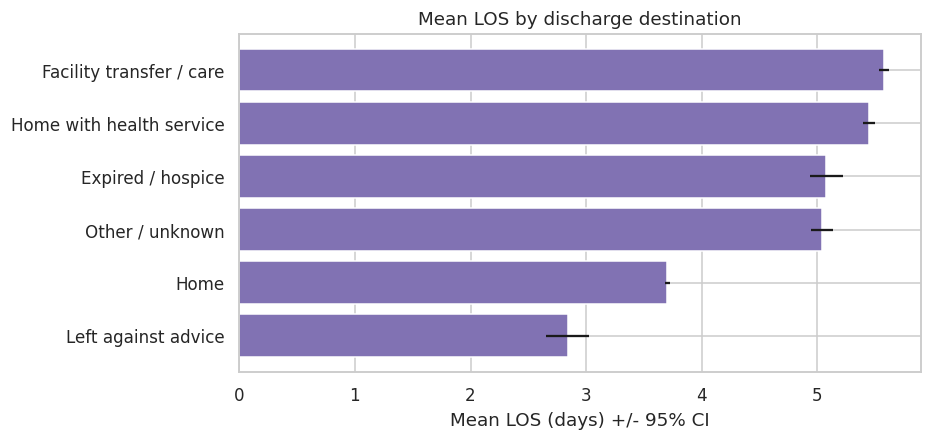

In [16]:
g=df.groupby('discharge_group').time_in_hospital; t=pd.DataFrame({'mean':g.mean(),'ci':1.96*g.std()/np.sqrt(g.size())}).sort_values('mean')
plt.figure(figsize=(8,4)); plt.barh(t.index,t['mean'],xerr=t.ci,color='#8172b3'); plt.xlabel('Mean LOS (days) +/- 95% CI'); plt.title('Mean LOS by discharge destination'); plt.show()

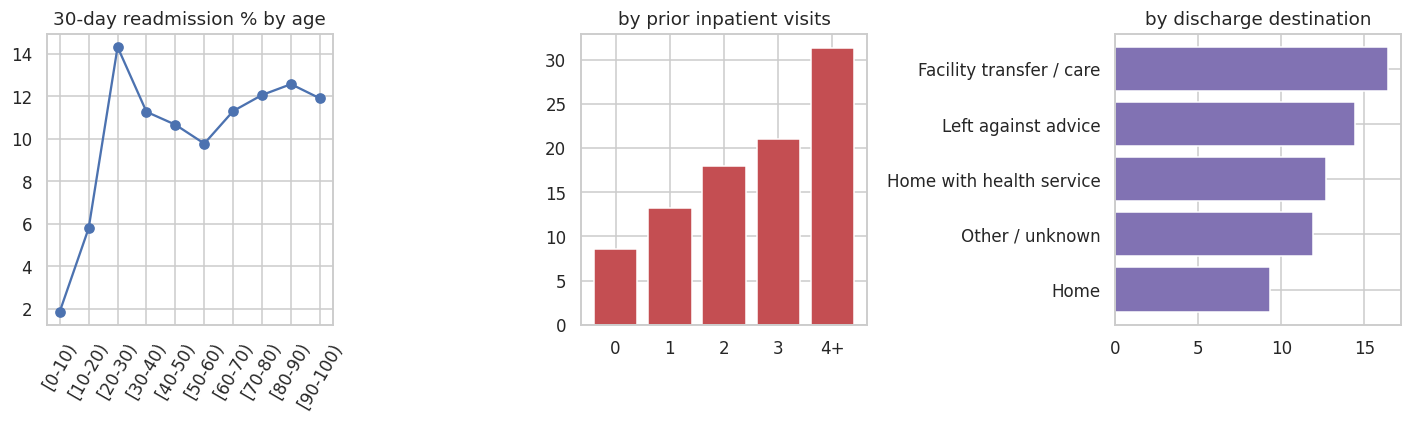

In [17]:
fig,ax = plt.subplots(1,3,figsize=(13,4))
r=rd.groupby('age',observed=True).readmit_30.mean()*100; ax[0].plot(range(len(r)),r.values,marker='o'); ax[0].set_xticks(range(len(r))); ax[0].set_xticklabels(r.index,rotation=60); ax[0].set_title('30-day readmission % by age')
inp=rd.number_inpatient.clip(upper=4); r=rd.groupby(inp).readmit_30.mean()*100; ax[1].bar(['0','1','2','3','4+'],r.values,color='#c44e52'); ax[1].set_title('by prior inpatient visits')
r=rd.groupby('discharge_group').readmit_30.mean().sort_values()*100; ax[2].barh(r.index,r.values,color='#8172b3'); ax[2].set_title('by discharge destination'); plt.tight_layout(); plt.show()

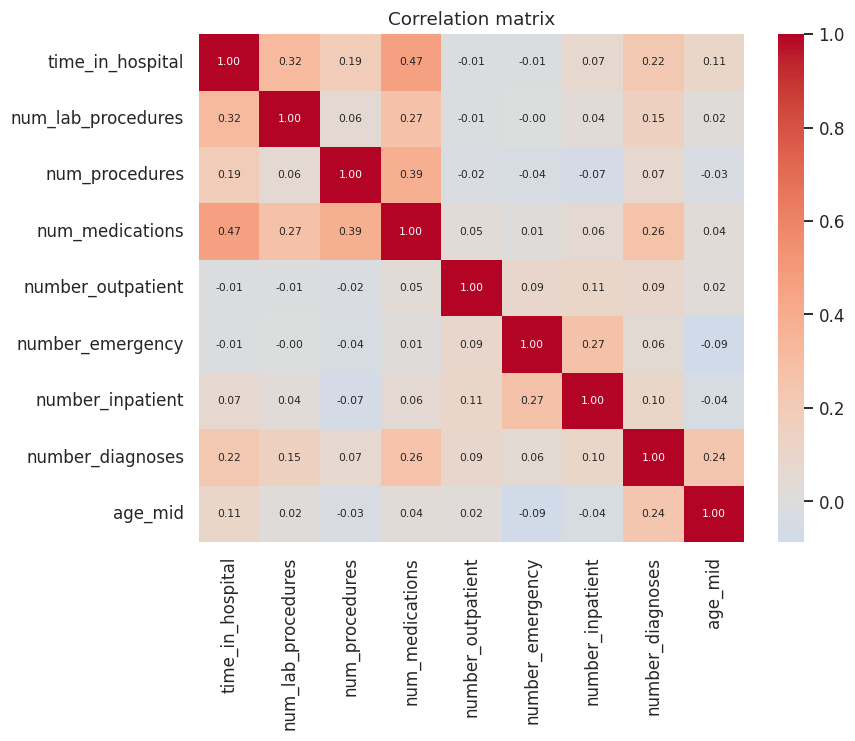

In [18]:
num=['time_in_hospital','num_lab_procedures','num_procedures','num_medications','number_outpatient','number_emergency','number_inpatient','number_diagnoses','age_mid']
plt.figure(figsize=(8,6)); sns.heatmap(df[num].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0,annot_kws={'size':7}); plt.title('Correlation matrix'); plt.show()

## 6. Statistical analysis

In [19]:
m=los.mean(); se=los.std()/np.sqrt(len(los)); print(f'Mean LOS 95% CI: {m-1.96*se:.2f} - {m+1.96*se:.2f}')
# LOS segments with 95% CI half-width (objective: >=5 segments)
rows=[]
for col in ['admission_type','discharge_group','age']:
    g=df.groupby(col,observed=True).time_in_hospital
    for k,s in g:
        if len(s)>=500: rows.append((col,k,len(s),s.mean(),s.median(),1.96*s.std()/np.sqrt(len(s))))
seg=pd.DataFrame(rows,columns=['dimension','segment','n','mean','median','ci_halfwidth']).round(3); seg

Mean LOS 95% CI: 4.38 - 4.41


,dimension,segment,n,mean,median,ci_halfwidth
0,admission_type,Elective,18868,4.321,3.0,0.044
1,admission_type,Emergency,53988,4.378,4.0,0.025
2,admission_type,Not available,10396,4.244,3.0,0.056
3,admission_type,Urgent,18480,4.611,4.0,0.044
4,discharge_group,Expired / hospice,2423,5.079,4.0,0.141
5,discharge_group,Facility transfer / care,20765,5.574,5.0,0.043
6,discharge_group,Home,60232,3.701,3.0,0.021
7,discharge_group,Home with health service,13010,5.449,5.0,0.053
8,discharge_group,Left against advice,623,2.839,2.0,0.187
9,discharge_group,Other / unknown,4710,5.040,4.0,0.093


In [20]:
eg=[g.time_in_hospital.values for _,g in df[df.admission_type.isin(['Emergency','Urgent','Elective'])].groupby('admission_type')]
print('ANOVA LOS ~ admission type:', stats.f_oneway(*eg)); print('Kruskal:', stats.kruskal(*eg))
print('Kruskal LOS ~ age:', stats.kruskal(*[g.time_in_hospital.values for _,g in df.groupby('age',observed=True)]))
print('Kruskal LOS ~ discharge:', stats.kruskal(*[g.time_in_hospital.values for _,g in df.groupby('discharge_group')]))
a=rd[rd.readmit_30==1].time_in_hospital; b=rd[rd.readmit_30==0].time_in_hospital
print(f'LOS readmitted<30 {a.mean():.2f} vs others {b.mean():.2f}:', stats.ttest_ind(a,b,equal_var=False), stats.mannwhitneyu(a,b))

ANOVA LOS ~ admission type: F_onewayResult(statistic=np.float64(53.0311412733454), pvalue=np.float64(9.599095549238109e-24))
Kruskal: KruskalResult(statistic=np.float64(132.91660500309413), pvalue=np.float64(1.3725429611283848e-29))
Kruskal LOS ~ age: KruskalResult(statistic=np.float64(1582.7820999397304), pvalue=np.float64(0.0))
Kruskal LOS ~ discharge: KruskalResult(statistic=np.float64(9641.819903421465), pvalue=np.float64(0.0))


LOS readmitted<30 4.77 vs others 4.33: TtestResult(statistic=np.float64(14.52530637364035), pvalue=np.float64(1.830616026737744e-47), df=np.float64(14229.369075659235)) MannwhitneyuResult(statistic=np.float64(545465728.0), pvalue=np.float64(1.5879284098807963e-62))


In [21]:
def chi(col):
    ct=pd.crosstab(rd[col],rd.readmit_30); c2,p,dof,_=stats.chi2_contingency(ct); v=np.sqrt(c2/(ct.values.sum()*(min(ct.shape)-1)))
    return dict(variable=col,chi2=round(c2,2),dof=dof,p=p,cramers_v=round(v,3))
pd.DataFrame([chi(c) for c in ['age','admission_type','discharge_group','primary_diag_group','gender']])

,variable,chi2,dof,p,cramers_v
0,age,133.62,9,2.128621e-24,0.037
1,admission_type,29.99,5,1.479227e-05,0.017
2,discharge_group,807.95,4,1.452908e-173,0.090
3,primary_diag_group,85.47,9,1.316100e-14,0.029
4,gender,0.63,1,4.283750e-01,0.003


In [22]:
for c in ['num_medications','num_lab_procedures','number_diagnoses','num_procedures','age_mid']:
    r,p=stats.pearsonr(df.time_in_hospital,df[c]); print(f'LOS vs {c:20s} r={r:.3f}  p={p:.2g}')
print('Spearman LOS vs medications:', stats.spearmanr(df.time_in_hospital,df.num_medications))

LOS vs num_medications      r=0.466  p=0
LOS vs num_lab_procedures   r=0.318  p=0
LOS vs number_diagnoses     r=0.220  p=0
LOS vs num_procedures       r=0.191  p=0
LOS vs age_mid              r=0.108  p=2.8e-259
Spearman LOS vs medications: SignificanceResult(statistic=np.float64(0.46509829678939785), pvalue=np.float64(0.0))


## 7. Key insights
1. Emergency admissions (~53%) entered mainly via the ER (~56.5%) dominate hospital demand.
2. ~67% of encounters are aged 60+; older patients stay longer (mean 2.55 days at 0-10 vs 4.81 at 80-90).
3. Discharge to a facility or home with health services means ~1.8-1.9 extra bed-days versus discharge home.
4. Medications (r=0.47) and lab procedures (r=0.32) are the strongest correlates of LOS.
5. 30-day readmission is 11.4% overall; it rises from 8.6% (no prior inpatient visits) to 31.4% (4+), and is 16.4% after facility discharge vs 9.3% after home discharge.
6. Gender has no significant effect on readmission; other effects are significant but small (Cramer's V <= 0.09).

**Limitations:** no dates (no calendar trends), 1999-2008 US diabetic patients only, repeated encounters per patient (~23%), descriptive/associational analysis only.